JKO MINIMIZATION VERIFICATION

 sigma_k  tau  Positive_Root  Negative_Root  Numerical_Minimizer  Minimizer_Error  Derivative_At_Root  Second_Derivative  Quadratic_Residual  Sigma_Increased
     0.5 0.01       0.519258      -0.019258             0.519258     5.942358e-12       -1.554312e-15         103.708798        8.673617e-18             True
     0.5 0.10       0.653113      -0.153113             0.653113     1.066542e-09       -2.220446e-16          12.344356       -2.775558e-17             True
     1.0 0.01       1.009902      -0.009902             1.009902     2.388575e-09        1.454392e-14         100.980486        2.307182e-16             True
     1.0 0.10       1.091608      -0.091608             1.091608     2.659879e-10        1.110223e-15          10.839202        8.326673e-17             True
     1.0 0.50       1.366025      -0.366025             1.366025     9.422909e-10       -1.110223e-16           2.535898        0.000000e+00             True
     2.0 0.10       2

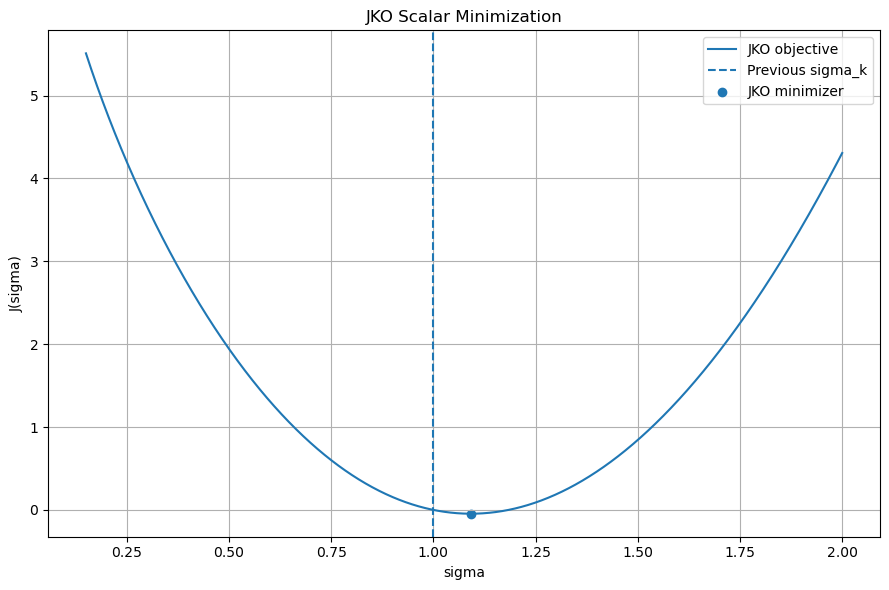

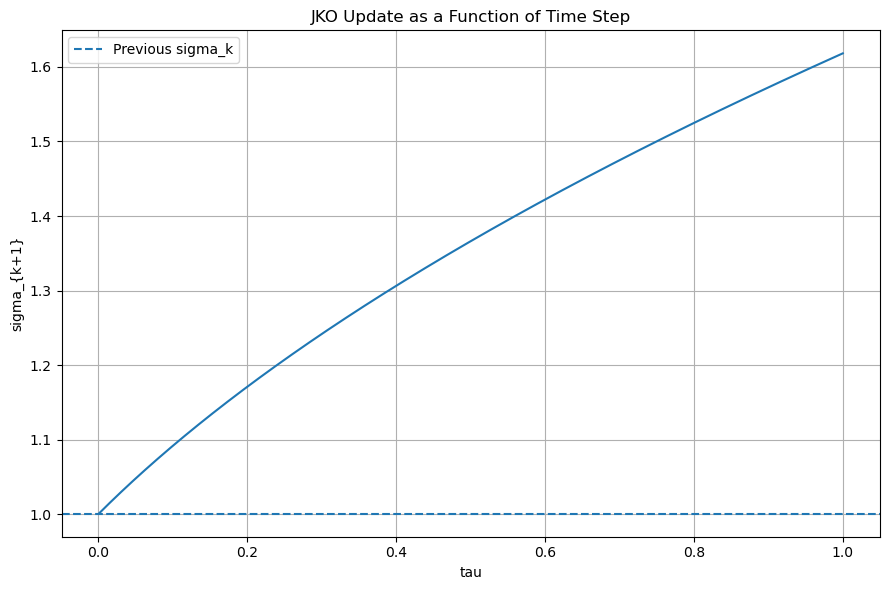


FINAL RESULT

sigma_{k+1}
= [sigma_k + sqrt(sigma_k^2 + 4 tau)] / 2

The negative quadratic root is discarded because sigma must be positive.


In [1]:
# ============================================================
# HOMEWORK 4.2 - PART III
# JKO MINIMIZATION
# STANDALONE VERIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize_scalar


# ============================================================
# JKO OBJECTIVE
#
# J(sigma)
#
# =
#
# -log(sigma)
#
# +
#
# (sigma - sigma_k)^2 / (2 tau)
# ============================================================

def jko_objective(
    sigma,
    sigma_k,
    tau
):

    if sigma <= 0:

        return np.inf


    return (

        -np.log(
            sigma
        )

        +

        (
            sigma
            -
            sigma_k
        )**2

        /

        (
            2.0
            *
            tau
        )
    )


# ============================================================
# FIRST DERIVATIVE
# ============================================================

def jko_derivative(
    sigma,
    sigma_k,
    tau
):

    return (

        -1.0
        /
        sigma

        +

        (
            sigma
            -
            sigma_k
        )

        /
        tau
    )


# ============================================================
# SECOND DERIVATIVE
# ============================================================

def jko_second_derivative(
    sigma,
    tau
):

    return (

        1.0
        /
        sigma**2

        +

        1.0
        /
        tau
    )


# ============================================================
# EXPLICIT JKO ROOTS
# ============================================================

def jko_roots(
    sigma_k,
    tau
):

    discriminant = np.sqrt(

        sigma_k**2

        +

        4.0
        *
        tau
    )


    positive_root = (

        sigma_k

        +

        discriminant

    ) / 2.0


    negative_root = (

        sigma_k

        -

        discriminant

    ) / 2.0


    return (
        positive_root,
        negative_root
    )


# ============================================================
# TEST CASES
# ============================================================

test_cases = [

    (0.5, 0.01),
    (0.5, 0.10),

    (1.0, 0.01),
    (1.0, 0.10),
    (1.0, 0.50),

    (2.0, 0.10),
    (2.0, 0.50),

    (3.0, 1.00)

]


results = []


for sigma_k, tau in test_cases:

    (
        sigma_explicit,
        sigma_negative

    ) = jko_roots(

        sigma_k,
        tau
    )


    # ========================================================
    # NUMERICAL MINIMIZATION
    # ========================================================

    upper_bound = (

        sigma_k

        +

        10.0

        *

        np.sqrt(
            tau
        )

        +

        5.0
    )


    numerical_result = minimize_scalar(

        jko_objective,

        bounds=(
            1e-10,
            upper_bound
        ),

        args=(
            sigma_k,
            tau
        ),

        method="bounded",

        options={
            "xatol": 1e-13
        }
    )


    sigma_numerical = (
        numerical_result.x
    )


    # ========================================================
    # FIRST-ORDER CONDITION
    # ========================================================

    derivative_at_root = jko_derivative(

        sigma_explicit,
        sigma_k,
        tau
    )


    # ========================================================
    # SECOND-DERIVATIVE CHECK
    # ========================================================

    second_derivative = jko_second_derivative(

        sigma_explicit,
        tau
    )


    # ========================================================
    # QUADRATIC EQUATION CHECK
    #
    # sigma^2 - sigma_k sigma - tau = 0
    # ========================================================

    quadratic_residual = (

        sigma_explicit**2

        -

        sigma_k
        *
        sigma_explicit

        -

        tau
    )


    # ========================================================
    # COMPARE EXPLICIT AND NUMERICAL MINIMIZERS
    # ========================================================

    minimizer_error = (

        sigma_numerical

        -

        sigma_explicit
    )


    results.append({

        "sigma_k":
            sigma_k,

        "tau":
            tau,

        "Positive_Root":
            sigma_explicit,

        "Negative_Root":
            sigma_negative,

        "Numerical_Minimizer":
            sigma_numerical,

        "Minimizer_Error":
            minimizer_error,

        "Derivative_At_Root":
            derivative_at_root,

        "Second_Derivative":
            second_derivative,

        "Quadratic_Residual":
            quadratic_residual,

        "Sigma_Increased":
            sigma_explicit > sigma_k

    })


results_df = pd.DataFrame(
    results
)


# ============================================================
# PRINT RESULTS
# ============================================================

print("=" * 100)

print(
    "JKO MINIMIZATION VERIFICATION"
)

print("=" * 100)

print()

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# ERROR SUMMARIES
# ============================================================

max_minimizer_error = np.max(

    np.abs(

        results_df[
            "Minimizer_Error"
        ]
    )
)


max_derivative_error = np.max(

    np.abs(

        results_df[
            "Derivative_At_Root"
        ]
    )
)


max_quadratic_residual = np.max(

    np.abs(

        results_df[
            "Quadratic_Residual"
        ]
    )
)


minimum_second_derivative = np.min(

    results_df[
        "Second_Derivative"
    ]
)


print()

print("=" * 100)

print(
    "AUTOMATIC VERIFICATION"
)

print("=" * 100)

print(
    "Maximum explicit-vs-numerical minimizer error =",
    max_minimizer_error
)

print(
    "Maximum |J'(sigma_{k+1})| =",
    max_derivative_error
)

print(
    "Maximum quadratic residual =",
    max_quadratic_residual
)

print(
    "Minimum J''(sigma_{k+1}) =",
    minimum_second_derivative
)


# ============================================================
# ROOT CHECKS
# ============================================================

assert np.all(

    results_df[
        "Positive_Root"
    ]
    >
    0
)


assert np.all(

    results_df[
        "Negative_Root"
    ]
    <
    0
)


print()

print(
    "PASS: The positive quadratic root is admissible."
)

print(
    "PASS: The negative quadratic root is not admissible."
)


# ============================================================
# CRITICAL-POINT CHECK
# ============================================================

assert max_derivative_error < 1e-10

assert max_quadratic_residual < 1e-10


print(
    "PASS: The explicit root satisfies J'(sigma) = 0."
)

print(
    "PASS: The explicit root satisfies the quadratic equation."
)


# ============================================================
# CONVEXITY CHECK
# ============================================================

assert minimum_second_derivative > 0


print(
    "PASS: J''(sigma) > 0, so the objective is strictly convex."
)


# ============================================================
# SPREADING CHECK
# ============================================================

assert np.all(

    results_df[
        "Sigma_Increased"
    ]
)


print(
    "PASS: Every JKO step increases sigma."
)


# ============================================================
# NUMERICAL OPTIMIZER CHECK
# ============================================================

if max_minimizer_error < 1e-6:

    print(
        "PASS: Numerical minimization agrees with "
        "the explicit JKO formula."
    )


# ============================================================
# EXAMPLE OBJECTIVE PLOT
#
# sigma_k = 1
# tau = 0.1
# ============================================================

sigma_k_example = 1.0

tau_example = 0.1


(
    sigma_star,
    sigma_negative

) = jko_roots(

    sigma_k_example,
    tau_example
)


sigma_plot = np.linspace(
    0.15,
    2.0,
    2000
)


J_plot = np.array([

    jko_objective(
        sigma,
        sigma_k_example,
        tau_example
    )

    for sigma in sigma_plot
])


plt.figure(
    figsize=(9, 6)
)


plt.plot(
    sigma_plot,
    J_plot,
    label="JKO objective"
)


plt.axvline(
    sigma_k_example,
    linestyle="--",
    label="Previous sigma_k"
)


plt.scatter(
    [sigma_star],
    [
        jko_objective(
            sigma_star,
            sigma_k_example,
            tau_example
        )
    ],
    label="JKO minimizer"
)


plt.xlabel(
    "sigma"
)

plt.ylabel(
    "J(sigma)"
)

plt.title(
    "JKO Scalar Minimization"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw42_part3_jko_minimization.png",
    dpi=300
)


plt.show()


# ============================================================
# JKO UPDATE VS tau
# ============================================================

sigma_k_fixed = 1.0


tau_values = np.linspace(
    0.001,
    1.0,
    1000
)


sigma_updates = (

    sigma_k_fixed

    +

    np.sqrt(

        sigma_k_fixed**2

        +

        4.0
        *
        tau_values
    )

) / 2.0


plt.figure(
    figsize=(9, 6)
)


plt.plot(
    tau_values,
    sigma_updates
)


plt.axhline(
    sigma_k_fixed,
    linestyle="--",
    label="Previous sigma_k"
)


plt.xlabel(
    "tau"
)

plt.ylabel(
    "sigma_{k+1}"
)

plt.title(
    "JKO Update as a Function of Time Step"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw42_part3_jko_update_vs_tau.png",
    dpi=300
)


plt.show()


# ============================================================
# FINAL RESULT
# ============================================================

print()

print("=" * 100)

print(
    "FINAL RESULT"
)

print("=" * 100)

print()

print(
    "sigma_{k+1}"
)

print(
    "= [sigma_k + sqrt(sigma_k^2 + 4 tau)] / 2"
)

print()

print(
    "The negative quadratic root is discarded "
    "because sigma must be positive."
)